# Compare RW Methods Visually on Small Hypergraphs

This notebook builds a few **small hypergraphs**, runs:
- `hyper2vec_embeddings`
- `clique_node2vec_embeddings`
- `hmrw_embeddings`

and visualizes the resulting node embeddings in 2D for quick qualitative comparison.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import xgi

from hypergraphx import Hypergraph
from sklearn.decomposition import PCA

from src.utils import hyper2vec_embeddings, clique_node2vec_embeddings, hmrw_embeddings

In [5]:
def make_toy_hypergraphs():
    """Return list of (name, Hypergraph, labels-array)."""
    toys = []

    # Two communities with one bridge hyperedge
    edges1 = [
        (0, 1, 2), (1, 2, 3), (0, 2, 3),
        (4, 5, 6), (5, 6, 7), (4, 6, 7),
        (2, 3, 4),
    ]
    H1 = Hypergraph(edges1)
    y1 = np.array([0, 0, 0, 0, 1, 1, 1, 1])
    toys.append(("Two clusters + bridge", H1, y1))

    # Ring-like overlap structure
    edges2 = [
        (0, 1, 2), (2, 3, 4), (4, 5, 6), (6, 7, 0),
        (1, 3, 5), (0, 4, 7),
    ]
    H2 = Hypergraph(edges2)
    y2 = np.array([0, 0, 1, 1, 2, 2, 3, 3])
    toys.append(("Overlapping ring", H2, y2))

    return toys


def draw_hypergraph_xgi(H, y, ax, title):
    """Draw hypergraph with xgi.draw (native hypergraph rendering)."""
    edges = [tuple(sorted(e)) for e in H.get_edges()]
    Hx = xgi.Hypergraph(edges)

    pos = xgi.spring_layout(Hx, seed=42)
    node_fc = {n: plt.cm.tab10(int(y[n]) % 10) for n in sorted(H.get_nodes())}

    xgi.draw(
        Hx,
        pos=pos,
        ax=ax,
        node_fc=node_fc,
        node_size=16,
        node_lw=0.8,
        edge_fc="lightsteelblue",
        edge_lw=1.4,
        edge_alpha=0.35,
        dyad_lw=1.2,
        hull=True,
    )

    # Overlay node ids for readability
    for n, (x0, y0) in pos.items():
        ax.text(x0, y0, str(n), fontsize=8, ha="center", va="center")

    ax.set_title(title)
    ax.set_axis_off()

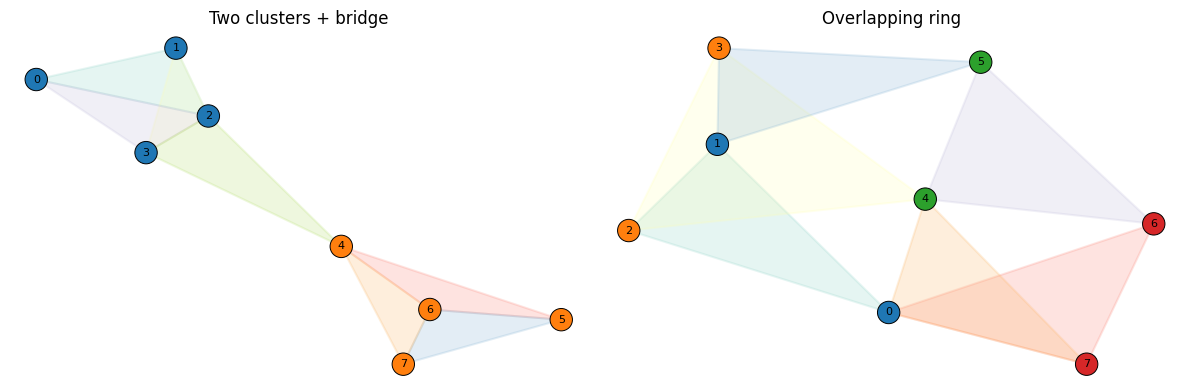

In [6]:
toys = make_toy_hypergraphs()

fig, axes = plt.subplots(1, len(toys), figsize=(6 * len(toys), 4))
if len(toys) == 1:
    axes = [axes]

for ax, (name, H, y) in zip(axes, toys):
    draw_hypergraph_xgi(H, y, ax, name)

fig.tight_layout()
plt.show()

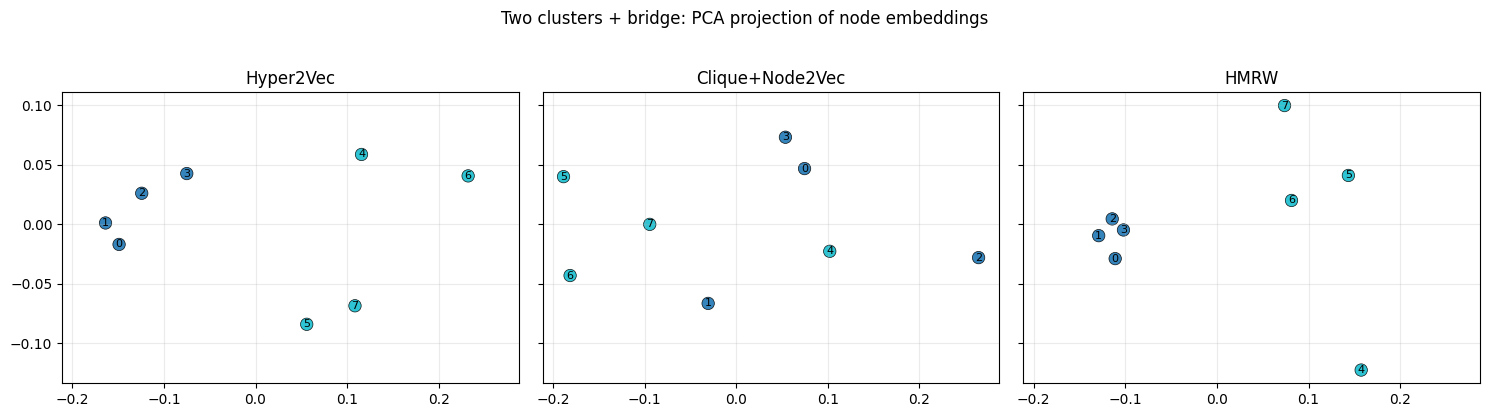

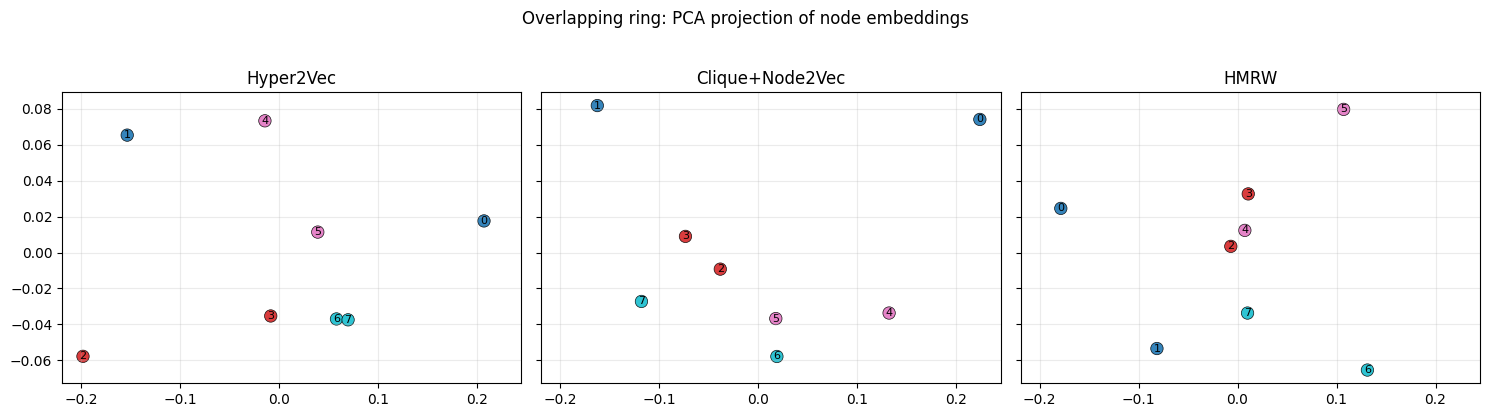

In [4]:
# Shared embedding params for fair visual comparison
emb_params = dict(num_walks=10, walk_length=20, window=5, dim=32, workers=1)

methods = {
    "Hyper2Vec": lambda H, s: hyper2vec_embeddings(H, p=1.0, q=1.0, r=0.0, seed=s, **emb_params),
    "Clique+Node2Vec": lambda H, s: clique_node2vec_embeddings(H, p=1.0, q=1.0, seed=s, **emb_params),
    "HMRW": lambda H, s: hmrw_embeddings(H, p=2.0, q=2.0, r=1.0, seed=s, **emb_params),
}

seed = 42

for toy_name, H, y in toys:
    fig, axes = plt.subplots(1, len(methods), figsize=(5 * len(methods), 4), sharex=True, sharey=True)
    if len(methods) == 1:
        axes = [axes]

    for ax, (method_name, fn) in zip(axes, methods.items()):
        X = fn(H, seed)
        Z = PCA(n_components=2, random_state=seed).fit_transform(X)

        ax.scatter(
            Z[:, 0], Z[:, 1],
            c=y, cmap="tab10", s=80,
            edgecolors="black", linewidths=0.5, alpha=0.9,
        )
        for i, (x0, x1) in enumerate(Z):
            ax.text(x0, x1, str(i), fontsize=8, ha="center", va="center")

        ax.set_title(method_name)
        ax.grid(alpha=0.25)

    fig.suptitle(f"{toy_name}: PCA projection of node embeddings", y=1.03)
    fig.tight_layout()
    plt.show()